# PharmaML — The Complete Docking Workflow (Zero to One Hundred)

One notebook, every stage of a molecular-docking campaign, in the order you
would actually run it:

| § | Stage | Toolkit |
|---|---|---|
| 1 | **Import the ligand library** — CSV in, validated library out | `pharmaml.docking` |
| 2 | **Import & prepare the protein** — PDB in, receptor PDBQT out | `pharmaml.docking` |
| 3 | Ligand preparation — SMILES → 3D PDBQT | `pharmaml.docking` |
| 4 | Grid box & GPF — enclose the binding site | `pharmaml.docking` |
| 5 | Run the engines — AutoDock4 / Vina (guarded) | `pharmaml.docking` |
| 6 | Parse AutoDock4 results — clusters, audit, campaign scan | `pharmaml.docking` |
| 7 | Torsion QA & campaign housekeeping — audit the tree before the next run | `pharmaml.docking` |
| 8 | Parse Vina output — pose tables | `pharmaml.docking` |
| 9 | Rescoring — ligand efficiency + consensus | `pharmaml.docking` |
| 10 | Visualization — energy distribution, top ligands | `pharmaml.viz` |
| 11 | Publish — one-click HTML report + csv/md exports | `pharmaml.viz` |
| 12 | Ligand-structure & MGLTools twins — ligprep.py / ligprep_qt.py (2026-10 upload) | `pharmaml.docking` |
| 12 | Ligand-structure & MGLTools twins — ligprep.py / ligprep_qt.py (2026-10 upload) | `pharmaml.docking` |

**Setup** — the parsing/analysis path needs only the core package; ligand
**and** protein preparation additionally need RDKit + Meeko:

```bash
pip install -e ".[reports]"        # core + plotting
pip install rdkit meeko gemmi       # §1–§3 preparation
```

The demo campaign below is *synthetic but structurally identical* to real
AutoDock4 output — 14 folders shipped under `examples/data/
docking_campaign/` (12 complete runs + two planted audit cases) — so every
cell runs without a docking engine installed.
Point `DOCKING_DIR` at **your** campaign folder and re-run — the parsers,
rescoring and plots work unchanged on real `.dlg` trees.


In [1]:
import tempfile
import warnings
from dataclasses import asdict
from pathlib import Path

import pandas as pd

from pharmaml import __version__

pd.set_option("display.max_columns", 14)
pd.set_option("display.width", 120)

# Silence the fork() DeprecationWarning the process pool emits on this
# Python build (harmless here, noisy in committed outputs).
warnings.filterwarnings("ignore", message=".*use of fork.*")

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="docking_workflow_"))

# The shipped demo inventory: the ligand library, the receptor PDB and
# the demo campaign tree all live under examples/data/.
DATA_DIR = Path("data")

# RDKit's C++ parser prints errors for invalid SMILES; silence the noise
# (the pharmaml layer reports invalid rows explicitly).
try:
    from rdkit import RDLogger

    RDLogger.DisableLog("rdApp.*")
except ImportError:
    pass

print(f"pharmaml {__version__}")
print(f"artifacts -> {WORK}")


pharmaml 1.2.201
artifacts -> /tmp/docking_workflow_hdriv55x


## 1 · Import the ligand library — CSV in

The legacy workflow started from a `ligands.csv` with a hard-coded
`SMILES` column — three scripts in the rar archive did this job with
three slightly different behaviours (`smilestopdbqt.py`, `smiqt.py`,
`ligand_preparation_autodock4.py`). `load_ligand_csv` unifies them:

* the SMILES column is **auto-detected** (`SMILES`, `smiles`,
  `canonical_smiles`, ...); the ligand-name column too, falling back
  to row numbers,
* every SMILES is **syntax-checked with RDKit** before any 3D
  embedding happens, so a typo costs seconds, not a crashed batch,
* invalid rows are reported explicitly and exported to
  `failed_smiles.csv` — the one good idea in
  `ligand_preparation_autodock4.py`, kept.

`prepare_ligand_library` then turns the valid rows into the campaign
tree every downstream tool expects: **one folder per ligand, each
containing a prepared `l.pdbqt`** — exactly the layout the original
scripts created, and what `scan_docking_directory` audits in §6.

In [2]:
# A demo ligand library: 8 real drug-like molecules plus two
# deliberately broken rows, so the validation accounting has something
# to report. Swap this cell for your own CSV -- everything below runs
# unchanged.
LIGANDS_CSV = DATA_DIR / "ligand_library.csv"   # <- replace with your own file

ligand_table = pd.read_csv(LIGANDS_CSV)
print(f"ligand library <- {LIGANDS_CSV}  ({len(ligand_table)} rows)")
ligand_table


ligand library <- data/ligand_library.csv  (10 rows)


,name,SMILES
0,aspirin,CC(=O)Oc1ccccc1C(=O)O
1,ibuprofen,CC(C)Cc1ccc(cc1)C(C)C(=O)O
2,paracetamol,CC(=O)Nc1ccc(O)cc1
3,caffeine,Cn1cnc2c1c(=O)n(C)c(=O)n2C
4,naproxen,COc1ccc2cc(ccc2c1)C(C)C(=O)O
5,benzocaine,CCOC(=O)c1ccc(N)cc1
6,coumarin,O=C1Oc2ccccc2C=C1
7,vanillin,COc1cc(C=O)ccc1O
8,broken_row,not_a_smiles
9,empty_row,NaN


In [3]:
from pharmaml.docking import load_ligand_csv

library = load_ligand_csv(LIGANDS_CSV)
print(library)
library.frame

Ligand library
  source        : data/ligand_library.csv
  rows          : 10 (9 unique SMILES)
  smiles column : SMILES
  names         : yes
  valid         : 8
  invalid       : 2


,name,smiles,status,error
0,aspirin,CC(=O)Oc1ccccc1C(=O)O,valid,
1,ibuprofen,CC(C)Cc1ccc(cc1)C(C)C(=O)O,valid,
2,paracetamol,CC(=O)Nc1ccc(O)cc1,valid,
3,caffeine,Cn1cnc2c1c(=O)n(C)c(=O)n2C,valid,
4,naproxen,COc1ccc2cc(ccc2c1)C(C)C(=O)O,valid,
5,benzocaine,CCOC(=O)c1ccc(N)cc1,valid,
6,coumarin,O=C1Oc2ccccc2C=C1,valid,
7,vanillin,COc1cc(C=O)ccc1O,valid,
8,broken_row,not_a_smiles,invalid,RDKit could not parse this SMILES
9,empty_row,NaN,invalid,empty or non-text SMILES cell


In [4]:
# The invalid rows, with the reason -- and the failed_smiles.csv export
# the legacy script wrote after every batch:
if len(library.invalid_frame):
    print(library.invalid_frame[["name", "smiles", "error"]].to_string(index=False))
    failed_path = library.write_failures(WORK / "failed_smiles.csv")
    print(f"\ninvalid rows exported -> {failed_path.name}")
else:
    print("no invalid rows in this library")

      name       smiles                             error
broken_row not_a_smiles RDKit could not parse this SMILES
 empty_row          NaN     empty or non-text SMILES cell

invalid rows exported -> failed_smiles.csv


In [5]:
from pharmaml.docking import prepare_ligand_library

LIGAND_FOLDERS = WORK / "csv_ligand_prep"   # <- your campaign directory

prep = prepare_ligand_library(library, LIGAND_FOLDERS)
print(prep)
prep.frame[["folder", "name", "ok", "atoms", "torsdof"]]

Ligand batch preparation
  campaign dir : /tmp/docking_workflow_hdriv55x/csv_ligand_prep
  prepared     : 8 ligands (112 atoms, 22 total rotatable bonds)
  failed       : 2  -> failed_smiles.csv
  layout       : one folder per ligand, <name>/l.pdbqt (scan_docking_directory-ready)


,folder,name,ok,atoms,torsdof
0,01_aspirin,aspirin,True,14,4
1,02_ibuprofen,ibuprofen,True,16,5
2,03_paracetamol,paracetamol,True,13,2
3,04_caffeine,caffeine,True,14,0
4,05_naproxen,naproxen,True,18,4
5,06_benzocaine,benzocaine,True,14,4
6,07_coumarin,coumarin,True,11,0
7,08_vanillin,vanillin,True,12,3
8,,broken_row,False,0,0
9,,empty_row,False,0,0


In [6]:
# The campaign tree (one folder per ligand, l.pdbqt inside) --
# scan_docking_directory-ready, and the layout the §6 demo campaign
# imitates:
for entry in sorted(LIGAND_FOLDERS.iterdir()):
    print(f"  {entry.relative_to(WORK)}" + ("/" if entry.is_dir() else ""))

  csv_ligand_prep/01_aspirin/
  csv_ligand_prep/02_ibuprofen/
  csv_ligand_prep/03_paracetamol/
  csv_ligand_prep/04_caffeine/
  csv_ligand_prep/05_naproxen/
  csv_ligand_prep/06_benzocaine/
  csv_ligand_prep/07_coumarin/
  csv_ligand_prep/08_vanillin/
  csv_ligand_prep/failed_smiles.csv


## 2 · Import & prepare the protein — PDB in, receptor PDBQT out

The rar scripts assumed the hard part was already done: `gpfer.py`
hard-coded `receptor_types = "A C HD N NA OA SA"` and a ready-made
`r.pdbqt` in every ligand folder, prepared *outside* the codebase with
the retired AutoDockTools. `prepare_protein` brings that step into the
package:

* import a protein from a PDB file (or an already-prepared PDBQT
  receptor),
* clean it — waters, non-protein HETATM records (ions, buffers,
  glycans), alternate-location conformers, chain selection,
* write a rigid receptor PDBQT with **AutoDock4 atom types, Gasteiger
  partial charges and polar hydrogens** via Meeko's polymer pipeline,
* audit every atom that went in, came out, or was dropped.

Demo input: hen egg-white lysozyme (PDB entry
[1AKI](https://www.rcsb.org/1AKI), public domain) — *the* classic
docking-tutorial receptor — with its 78 crystallographic waters, plus a
sprinkling of the usual suspects a wet PDB contains (a chloride ion, a
sulfate, an alternate conformer) so every cleaning rule visibly fires.

`distribute_receptor` finally copies the prepared receptor into the §1
campaign folders — the job of the archive's `adder.py`, minus the
engine executables it also (needlessly) copied everywhere.

In [7]:
# Lysozyme 1AKI, shipped as examples/data/lysozyme_1aki.pdb (RCSB entry
# 1AKI, public domain).  The demo keeps just the 1001 ATOM + 78 HETATM
# records; in practice you start from your own source: an RCSB download,
# a crystallography collaborator, an AlphaFold export, ...
PROTEIN_PDB = WORK / "lysozyme_wet.pdb"   # doctored in the next cell, never the shipped file

LYSOZYME_PDB_TEXT = "".join(
    line + "\n"
    for line in (DATA_DIR / "lysozyme_1aki.pdb").read_text(encoding="utf-8").splitlines()
    if line.startswith(("ATOM", "HETATM"))
)
PROTEIN_PDB.write_text(LYSOZYME_PDB_TEXT, encoding="utf-8")
n_atom = LYSOZYME_PDB_TEXT.count("ATOM")
n_het = LYSOZYME_PDB_TEXT.count("HETATM")
print(f"{PROTEIN_PDB.name}: {n_atom} ATOM + {n_het} HETATM records")


lysozyme_wet.pdb: 1001 ATOM + 78 HETATM records


In [8]:
from collections import Counter

atom_records = [l for l in PROTEIN_PDB.read_text().splitlines()
                if l.startswith(("ATOM", "HETATM"))]
hetatm_residues = Counter(
    l[17:20].strip() for l in atom_records if l.startswith("HETATM")
)
print(f"{sum(1 for l in atom_records if l.startswith('ATOM')):5d} ATOM   records  (the polymer)")
for res, count in sorted(hetatm_residues.items()):
    print(f"{count:5d} HETATM records  ({res})")

 1001 ATOM   records  (the polymer)
   78 HETATM records  (HOH)


In [9]:
def _hetatm(serial, name, resname, chain, resseq, x, y, z, element):
    return (
        f"HETATM{serial:5d} {name:>4s} {resname:>3s} {chain}{resseq:4d}    "
        f"{x:8.3f}{y:8.3f}{z:8.3f}{1.0:6.2f}{0.0:6.2f}          {element:>2s}"
    )

# 1AKI is unusually clean, so we sprinkle in what a typical wet PDB
# carries: a chloride counter-ion, a sulfate from the crystallization
# buffer, and an alternate conformer (altloc B) of an existing atom.
lines = PROTEIN_PDB.read_text().splitlines()
wet = list(lines)
wet.append(_hetatm(2001, "CL", "CL", "A", 301, 20.0, 20.0, 20.0, "Cl"))
for i, (nm, x, y, z) in enumerate(
    [("S", 21, 21, 21), ("O1", 22, 21, 21), ("O2", 20, 21, 21),
     ("O3", 21, 22, 21), ("O4", 21, 20, 21)]
):
    element = "S" if nm == "S" else "O"
    wet.append(_hetatm(2002 + i, nm, "SO4", "A", 302, float(x), float(y), float(z), element))
clone = list(lines[10])          # duplicate one atom as alternate conformer B
clone[16] = "B"
wet.insert(11, "".join(clone))
PROTEIN_PDB.write_text("\n".join(wet) + "\nTER\nEND\n", encoding="utf-8")
print(f"doctored input: {len(wet)} records (was {len(lines)})")

doctored input: 1086 records (was 1079)


In [10]:
from pharmaml.docking import prepare_protein

RECEPTOR = WORK / "r.pdbqt"     # the filename gpfer.py's GPF lines expect
protein = prepare_protein(PROTEIN_PDB, RECEPTOR)
print(protein)

Protein preparation audit
  source          : /tmp/docking_workflow_hdriv55x/lysozyme_wet.pdb
  mode            : meeko (Meeko polymer pipeline)
  input           : 1002 ATOM + 84 HETATM records
  removed         : 78 water, 6 non-protein HETATM, 1 alt-location, 0 input H
  chains kept     : A
  residues        : 129
  receptor        : 1262 atoms -> r.pdbqt
  atom types      : A×87  C×526  HD×261  N×192  NA×1  OA×185  SA×10
  charges         : [-0.549, +0.345] (mean +0.006)


In [11]:
from pharmaml.docking import extract_pdbqt_atom_types

receptor_lines = RECEPTOR.read_text().splitlines()
print("\n".join(receptor_lines[:4]))
print(f"... ({len(receptor_lines)} lines total)\n")

# The seven types gpfer.py hard-coded ("A C HD N NA OA SA") -- now
# derived from the actual receptor instead of assumed:
print("receptor atom types:", extract_pdbqt_atom_types(RECEPTOR))
pd.Series(protein.atom_types).sort_values(ascending=False).to_frame("count")

ATOM      1  C   LYS A   1      34.741  20.264 -10.844  1.00  0.00    +0.242 C 
ATOM      2  O   LYS A   1      33.945  20.813 -10.081  1.00  0.00    -0.273 OA
ATOM      3  CA  LYS A   1      35.892  21.073 -11.427  1.00  0.00    +0.171 C 
ATOM      4  N   LYS A   1      35.365  22.342 -11.980  1.00  0.00    -0.344 N 
... (1262 lines total)

receptor atom types: ['A', 'C', 'HD', 'N', 'NA', 'OA', 'SA']


,count
C,526
HD,261
N,192
OA,185
A,87
SA,10
NA,1


«venv»/lib/python3.12/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  prop = Group((name + Suppress("=") + comma_separated(value)) | oneOf(_CONSTANTS))
«venv»/lib/python3.12/site-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
«venv»/lib/python3.12/site-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
«venv»/lib/python3.12/site-packages/matplotlib/_mathtext.py:45: PyparsingDeprecationWarning: 'enablePackrat' deprecated - use 'enable_packrat'
  ParserElement.enablePackrat()
In «venv»/lib/python3.12/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'parseString' deprecated - use 'parse_string'


In «venv»/lib/python3.12/site-packages/matplotlib/mpl-data/stylelib/classic.mplstyle: 'resetCache' deprecated - use 'reset_cache'


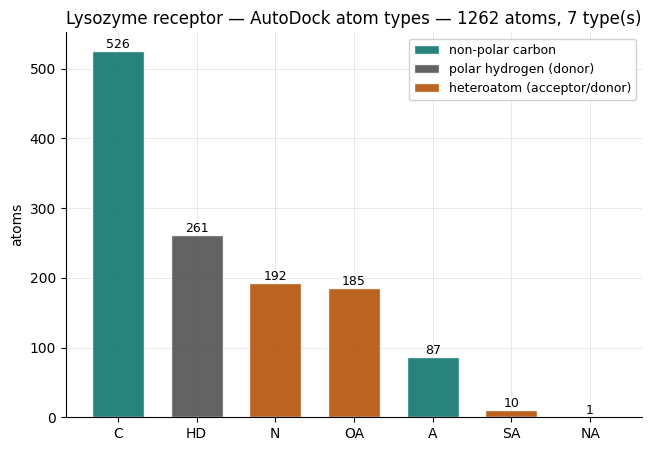

In [12]:
from pharmaml.viz import plot_receptor_atom_types

# The same census as a figure, colour-coded by chemistry — donor
# hydrogens, heteroatoms, non-polar carbons, metals/ions. A missing HD
# (donor) population is the classic symptom of a mis-prepared receptor:
receptor_fig = plot_receptor_atom_types(
    RECEPTOR, title="Lysozyme receptor — AutoDock atom types"
)

In [13]:
from pharmaml.docking import distribute_receptor

targets = distribute_receptor(RECEPTOR, LIGAND_FOLDERS)
print(f"r.pdbqt distributed into {len(targets)} ligand folders of §1's campaign"
      "  (adder.py's job, without the engine binaries)")

r.pdbqt distributed into 8 ligand folders of §1's campaign  (adder.py's job, without the engine binaries)


In [14]:
# Already have a prepared r.pdbqt from a collaborator or an older
# campaign? The same call re-filters it (waters, HETATM, altlocs)
# without any Meeko step -- charges and types pass through untouched:
passthrough = prepare_protein(RECEPTOR, WORK / "r_clean.pdbqt")
print(f"mode={passthrough.mode}, {passthrough.output_atoms} atoms, "
      f"charges kept: [{passthrough.charge_min:+.3f}, {passthrough.charge_max:+.3f}]")

mode=pdbqt, 1262 atoms, charges kept: [-0.549, +0.345]


## 3 · Ligand preparation — SMILES → 3D PDBQT

The legacy `smilestopdbqt.py` embedded paths and mutated global state;
`smiles_to_pdbqt` embeds each molecule with ETKDG, MMFF-optimises it, writes
the PDBQT through Meeko, and repairs any non-AD4 atom types — all with
explicit output directories.


In [15]:
from pharmaml.docking import smiles_to_pdbqt, extract_pdbqt_atom_types

LIGAND_DIR = WORK / "ligands"

# Three demo ligands (in your project: loop over your screening library).
for name, smi in [
    ("aspirin", "CC(=O)Oc1ccccc1C(=O)O"),
    ("ibuprofen", "CC(C)Cc1ccc(cc1)C(C)C(=O)O"),
    ("caffeine", "Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
]:
    path = smiles_to_pdbqt(smi, LIGAND_DIR, name=name)
    print(f"prepared {name:12s} -> {path.name}  ({path.stat().st_size} bytes)")

prepared aspirin      -> aspirin.pdbqt  (1411 bytes)
prepared ibuprofen    -> ibuprofen.pdbqt  (1639 bytes)
prepared caffeine     -> caffeine.pdbqt  (1302 bytes)


In [16]:
# The atom types Meeko wrote — these drive the affinity maps in §4.
for pdbqt in sorted(LIGAND_DIR.glob("*.pdbqt")):
    print(f"{pdbqt.stem:12s}: {extract_pdbqt_atom_types(pdbqt)}")

aspirin     : ['A', 'C', 'HD', 'OA']
caffeine    : ['A', 'C', 'N', 'NA', 'OA']
ibuprofen   : ['A', 'C', 'HD', 'OA']


In [17]:
# What a prepared ligand looks like (torsion tree + partial charges).
print((LIGAND_DIR / "aspirin.pdbqt").read_text()[:400])

REMARK SMILES CC(=O)Oc1ccccc1C(=O)O
REMARK SMILES IDX 5 1 6 2 7 3 8 4 9 5 10 6 4 7 2 8 3 9 1 10 11 11 12 12 13 13
REMARK H PARENT 13 14
ROOT
ATOM      1  C   UNL     1      -0.057  -0.533  -0.220  1.00  0.00    +0.145 A 
ATOM      2  C   UNL     1      -0.103  -1.931  -0.237  1.00  0.00    +0.048 A 
ATOM      3  C   UNL     1      -1.153  -2.594   0.395  1.00  0.00    +0.004 A 
ATOM      4  C   UN


## 4 · Grid box, GPF & DPF — enclose the binding site

`compute_grid_box` derives the search box from a co-crystallised (reference)
ligand plus padding — the calculation `gpfer.py` did by hand. `write_gpf`
then emits one AutoDock4 grid parameter file with an affinity-map line per
ligand atom type (extracted from the PDBQT itself).
The `receptor` line points at `r.pdbqt` — the file §2 prepared and
`distribute_receptor` copied into each ligand folder.


In [18]:
from pharmaml.docking import GridBox, compute_grid_box

# In a real project this is the CO-CRYSTALLISED ligand carved from the
# receptor PDB; here the aspirin we just prepared plays that role.
reference = LIGAND_DIR / "aspirin.pdbqt"

box = compute_grid_box(reference, padding=4.0)
print(f"centre : ({box.center_x:.2f}, {box.center_y:.2f}, {box.center_z:.2f}) A")
print(f"size   : {tuple(round(s, 1) for s in box.size)} A  "
      f"(npts {box.npts} @ {box.spacing} A spacing)")
print(f"vina   : {box.as_vina_kwargs()}")

centre : (0.46, 0.31, 0.13) A
size   : (22.1, 22.1, 22.1) A  (npts (60, 60, 60) @ 0.375 A spacing)
vina   : {'center_x': 0.46099999999999985, 'center_y': 0.31400000000000006, 'center_z': 0.1305, 'size_x': 22.125, 'size_y': 22.125, 'size_z': 22.125}


In [19]:
from pharmaml.docking import write_gpf

gpf = write_gpf(reference, receptor_file="r.pdbqt", box=box,
                output_path=WORK / "r.gpf")
print(gpf.read_text())

npts 60 60 60          # num.grid points in xyz
gridfld r.maps.fld                    # grid_data_file
spacing 0.375                        # spacing(A)
receptor_types A C HD N NA OA SA     # receptor atom types
ligand_types A C HD OA            # ligand atom types
receptor r.pdbqt                     # macromolecule
gridcenter 0.46099999999999985 0.31400000000000006 0.1305      # xyz-coordinates
smooth 0.5                           # store minimum energy w/in rad(A)
map r.A.map                          # atom-specific affinity map
map r.C.map                          # atom-specific affinity map
map r.HD.map                          # atom-specific affinity map
map r.OA.map                          # atom-specific affinity map
elecmap r.e.map                      # electrostatic potential map
dsolvmap r.d.map              # desolvation potential map
dielectric -0.1465                   # <0, AD4 distance-dep.diel;>0, constant



In [20]:
from pharmaml.docking import write_dpf

# The DPF is AutoDock4's per-ligand instruction sheet (upgrades dpfer.py):
# ligand atom types, the "about" rotation centre — the ligand centroid —
# TORSDOF, and the full Lamarckian GA + Solis-Wets local-search block.
# Every GA knob is a keyword argument; ga_run defaults to 100.
dpf = write_dpf(reference, receptor_file="r.pdbqt", ga_run=100,
                output_path=WORK / "r.dpf")
for line in dpf.read_text().splitlines():
    if line.startswith(("ligand_types", "move ", "about ", "torsdof",
                        "ga_run", "set_ga", "set_psw1", "analysis")):
        print(line)

ligand_types A C HD OA
move aspirin.pdbqt
about -0.258 0.314 0.284
torsdof 4
set_ga
set_psw1
ga_run 100
analysis


In [21]:
from pharmaml.docking import check_torsion_consistency, scan_torsion_consistency

# Torsion QA (upgrades ligprep_match.py / mismatch2.py): prepare_ligand4.py
# writes one active-torsion REMARK and one BRANCH record per rotatable
# bond, plus a final TORSDOF total — the ligand is only valid when they
# agree. The legacy scripts exported this audit to Excel with red fills;
# pharmaml returns a typed report and auto-detects the writer lineage
# (MGLTools three-way rule vs Meeko's TORSDOF == BRANCH invariant).
qa = check_torsion_consistency(reference)
print(f"reference : TORSDOF={qa.torsdof}  remarks={qa.active_remarks}  "
      f"branches={qa.branches}  ->  {qa.status()}")

# The MGLTools lineage demo — exactly what the rar scripts audited:
mgl_style = WORK / "mgl_style.pdbqt"
mgl_style.write_text(
    "REMARK  1  A    between atoms: T1_2-CA   T3_4-CB\n"
    "REMARK  2  A    between atoms: T5_6-CG   T7_8-CD\n"
    "ROOT\nATOM      1  C   LIG A   1       0.000   0.000   0.000  1.00  0.00     0.000 C\n"
    "ENDROOT\n"
    "BRANCH    1    2\nBRANCH    2    3\n"
    "TORSDOF 2\n",
    encoding="utf-8",
)
print("mgltools :", check_torsion_consistency(mgl_style).status(),
      "(all three counts agree)")
mgl_style.write_text(mgl_style.read_text().replace("TORSDOF 2", "TORSDOF 3"),
                     encoding="utf-8")
print("mgltools :", check_torsion_consistency(mgl_style).status(),
      "(TORSDOF lies — the mismatch the Excel report flagged red)")

torsion_frame = scan_torsion_consistency(LIGAND_DIR)
print(f"\nligands scanned: {len(torsion_frame)}")
print(torsion_frame.head(6).to_string(index=False))
assert (torsion_frame['status'] == 'OK').all(), 'torsion QA failed'

reference : TORSDOF=4  remarks=0  branches=4  ->  OK
mgltools : OK (all three counts agree)
mgltools : MISMATCH (TORSDOF lies — the mismatch the Excel report flagged red)

ligands scanned: 3
         ligand  torsdof  active_remarks  branches status
  aspirin.pdbqt        4               0         4     OK
 caffeine.pdbqt        0               0         0     OK
ibuprofen.pdbqt        5               0         5     OK


## 5 · Run the engines — AutoDock4 / Vina

`run_autodock4`, `run_vina` and `batch_run_directories` wrap the engines with
argument-list subprocess calls (no `shell=True`, no `os.chdir`), availability
checks *before* hours of queue time, and per-run timings.  Neither engine is
installed in this demo environment — the cell below shows the *actionable*
error you get instead of a cryptic crash:

> In a production environment (AutoDock Tools / Vina on `PATH`) the same
> calls return a `DockingRunResult` with timings and output paths.


In [22]:
from pharmaml.docking import run_autodock4, run_vina
from pharmaml.exceptions import DockingError

# AutoDock4 needs autogrid4/autodock4 on PATH; Vina needs `vina`.
for label, call in [
    ("run_vina", lambda: run_vina(
        receptor="r.pdbqt", ligand=reference, out=WORK / "aspirin_out.pdbqt",
        center=(box.center_x, box.center_y, box.center_z),
        size=box.size, seed=42,
    )),
    ("run_autodock4", lambda: run_autodock4(WORK)),   # r.gpf exists -> binary check fires
]:
    try:
        call()
    except DockingError as exc:
        print(f"[{label}] {exc}")

[run_vina] vina.exe is a Windows PE executable and no wine was found on PATH -- run it on Windows, install compatible wine, or use a native engine build


## 6 · Parse AutoDock4 results — clusters, audit, campaign scan

The parsers accept **text or paths** and return typed dataclasses /
DataFrames, so they are unit-testable without a docking engine — and so this
notebook can build a demo campaign whose `.dlg` files are byte-compatible
with the real format:

* `parse_dlg_cluster_table` — one ligand's cluster table (the
  `readerwithdetails.py` regex, now typed);
* `parse_dlg_summary` — best (lowest-energy) *and* most-populated cluster;
* `check_docking_completion` — the `checker.py` audit: every folder needs
  its `r.dlg` **and** the `Successful Completion` sentinel;
* `scan_docking_directory` — the whole campaign in one table, with explicit
  status columns for failed folders instead of a crash.

The demo tree includes one folder with **no log at all** and one
**interrupted** run, so the audit columns are exercised.  Finally,
`batch_run_directories` re-runs the whole campaign *idempotently*: a folder
whose `.dlg` already carries AutoDock's `Successful Completion` sentinel is
skipped (an interrupted log is re-run, never trusted just because the file
exists), and failures are collected as results (not raised) — the difference between a queued night job that
finishes and one that dies at folder 3.


In [23]:
# --- DEMO CAMPAIGN ------------------------------------------------------
# A synthetic AutoDock4 campaign shipped under examples/data/
# docking_campaign/ (regenerated deterministically by
# tools/build_example_data.py): one folder per ligand, each with an
# r.dlg whose cluster table uses the exact real format.  One folder is
# missing its log entirely and one was interrupted before clustering, so
# the audit has something to find.
#
# The notebook runs on a scratch COPY of the shipped tree: the §7
# housekeeping verbs collect files and preview cleanups *inside* the
# campaign root, and the shipped inventory itself must stay pristine
# (same pattern as the protein above).  (In your project: set
# DOCKING_DIR to your real campaign folder -- e.g. the tree §1-§2 just
# built -- and drop the copy step.)
import shutil

DOCKING_DIR = WORK / "docking_campaign"   # scratch copy, never the shipped tree
shutil.copytree(DATA_DIR / "docking_campaign", DOCKING_DIR)

# The campaign manifest (one (name, SMILES) row per folder) -- §9 maps
# ligand names back to structures through it.
CAMPAIGN_LIGANDS = list(
    pd.read_csv(DOCKING_DIR / "ligands.csv").itertuples(index=False, name=None)
)

n_folders = len([p for p in DOCKING_DIR.iterdir() if p.is_dir()])
print(f"demo campaign: {DATA_DIR / 'docking_campaign'} -> {DOCKING_DIR} (scratch copy)")
print(f"{n_folders} ligand folders (12 OK, 1 missing log, 1 interrupted)")


demo campaign: data/docking_campaign -> /tmp/docking_workflow_hdriv55x/docking_campaign (scratch copy)
14 ligand folders (12 OK, 1 missing log, 1 interrupted)


In [24]:
from pharmaml.docking import parse_dlg_cluster_table

clusters = parse_dlg_cluster_table(DOCKING_DIR / "01_aspirin" / "r.dlg")
pd.DataFrame([asdict(c) for c in clusters])

,rank,lowest_energy,mean_energy,num_in_cluster
0,1,-4.91,-4.74,15
1,2,-6.07,-5.58,13
2,3,-7.48,-7.06,8
3,4,-9.18,-8.87,13
4,5,-9.65,-9.58,6


In [25]:
from pharmaml.docking import parse_dlg_summary

summary_one = parse_dlg_summary(DOCKING_DIR / "01_aspirin" / "r.dlg")
for key, value in summary_one.items():
    print(f"{key:22s}: {value}")
print("\n'top_' = lowest energy overall; 'best_' = most populated cluster")

n_clusters            : 5
top_rank              : 1
top_lowest_energy     : -4.91
top_mean_energy       : -4.74
top_num_in_cluster    : 15
best_rank             : 1
best_lowest_energy    : -4.91
best_mean_energy      : -4.74
best_num_in_cluster   : 15

'top_' = lowest energy overall; 'best_' = most populated cluster


In [26]:
from pharmaml.docking import check_docking_completion

audit = check_docking_completion(DOCKING_DIR)
print(audit["status"].value_counts().to_dict(), "\n")
audit

{'OK': 12, 'MISSING_LOG': 1, 'INCOMPLETE': 1} 



,folder,status
0,01_aspirin,OK
1,02_ibuprofen,OK
2,03_naproxen,OK
3,04_paracetamol,OK
4,05_caffeine,OK
5,06_theophylline,OK
6,07_metformin,OK
7,08_benzocaine,MISSING_LOG
8,09_propranolol,OK
9,10_nicotine,INCOMPLETE


In [27]:
from pharmaml.docking import scan_docking_directory

summary = scan_docking_directory(DOCKING_DIR)
summary.round(2)

,folder,n_clusters,top_rank,top_lowest_energy,top_mean_energy,top_num_in_cluster,best_rank,best_lowest_energy,best_mean_energy,best_num_in_cluster,status
0,01_aspirin,5.0,1.0,-4.91,-4.74,15.0,1.0,-4.91,-4.74,15.0,OK
1,02_ibuprofen,5.0,1.0,-5.79,-5.60,11.0,4.0,-9.63,-9.15,15.0,OK
2,03_naproxen,5.0,1.0,-5.52,-5.23,8.0,3.0,-9.52,-9.06,13.0,OK
3,04_paracetamol,5.0,1.0,-5.68,-5.18,13.0,1.0,-5.68,-5.18,13.0,OK
4,05_caffeine,5.0,1.0,-4.56,-4.36,9.0,2.0,-7.14,-6.79,15.0,OK
5,06_theophylline,5.0,1.0,-4.63,-4.55,8.0,5.0,-11.51,-11.37,15.0,OK
6,07_metformin,5.0,1.0,-6.44,-5.94,7.0,3.0,-8.13,-7.96,19.0,OK
7,08_benzocaine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,MISSING_LOG
8,09_propranolol,5.0,1.0,-5.66,-5.06,9.0,4.0,-7.83,-7.41,13.0,OK
9,10_nicotine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PARSE_ERROR: no cluster table found in the pro...


In [28]:
import warnings

from pharmaml.docking import batch_run_directories

# IPython resets warning filters per cell, so scope the fork() noise here.
warnings.filterwarnings("ignore", message=".*use of fork.*")

# Idempotent campaign re-run: folders whose .dlg carries AutoDock's
# completion sentinel are skipped, per-folder failures are collected as
# results (benzocaine has no files at all; nicotine's interrupted log is
# re-attempted and fails loudly on its missing r.dpf) -- which is exactly
# why the completion audit above exists as a separate check.
for r in batch_run_directories(DOCKING_DIR, workers=2):
    status = "ok" if r.ok else f"FAILED: {r.error}"
    print(f"[batch] {r.directory.name:16s} -> {status}")


2/14 docking runs failed


[batch] 01_aspirin       -> ok
[batch] 02_ibuprofen     -> ok
[batch] 03_naproxen      -> ok
[batch] 04_paracetamol   -> ok
[batch] 05_caffeine      -> ok
[batch] 06_theophylline  -> ok
[batch] 07_metformin     -> ok
[batch] 08_benzocaine    -> FAILED: missing r.gpf in /tmp/docking_workflow_hdriv55x/docking_campaign/08_benzocaine
[batch] 09_propranolol   -> ok
[batch] 10_nicotine      -> FAILED: missing r.dpf in /tmp/docking_workflow_hdriv55x/docking_campaign/10_nicotine
[batch] 11_atenolol      -> ok
[batch] 12_lidocaine     -> ok
[batch] 13_coumarin      -> ok
[batch] 14_vanillin      -> ok


In [29]:
from pharmaml.docking import collect_files, reindex_by_number

# Campaign housekeeping (upgrades extaacer.py + Prettier_extracted_dlgs.py):
# gather every r.dlg of the tree into one folder, renamed after its
# ligand folder (with _1/_2 dedup suffixes) so results never overwrite…
collected = collect_files(DOCKING_DIR, filename="r.dlg")
print(collected[["folder", "destination", "copied"]].to_string(index=False))

# …then reindex the campaign summary onto the full ligand-number range
# so missing ligands surface as visible NaN rows instead of silently
# absent ones (00 here is the numbering gap by construction).
aligned = reindex_by_number(summary, column="folder", start=1, stop=14)
present = aligned["folder"].notna().sum()
print(f"\nsummary rows reindexed onto 1..14: {len(aligned)} "
      f"({int(present)} present, {len(aligned) - int(present)} missing)")

         folder                                                                   destination  copied
     01_aspirin      /tmp/docking_workflow_hdriv55x/docking_campaign/collected/01_aspirin.dlg    True
   02_ibuprofen    /tmp/docking_workflow_hdriv55x/docking_campaign/collected/02_ibuprofen.dlg    True
    03_naproxen     /tmp/docking_workflow_hdriv55x/docking_campaign/collected/03_naproxen.dlg    True
 04_paracetamol  /tmp/docking_workflow_hdriv55x/docking_campaign/collected/04_paracetamol.dlg    True
    05_caffeine     /tmp/docking_workflow_hdriv55x/docking_campaign/collected/05_caffeine.dlg    True
06_theophylline /tmp/docking_workflow_hdriv55x/docking_campaign/collected/06_theophylline.dlg    True
   07_metformin    /tmp/docking_workflow_hdriv55x/docking_campaign/collected/07_metformin.dlg    True
 09_propranolol  /tmp/docking_workflow_hdriv55x/docking_campaign/collected/09_propranolol.dlg    True
    10_nicotine     /tmp/docking_workflow_hdriv55x/docking_campaign/collected/10_n

## 7 · Torsion QA & campaign housekeeping — audit the tree before the next run

A campaign is rarely *one* run: ligands get hand-edited, folders get renamed,
results get collected and re-collected. Before queueing the next round, two
cheap audits catch the silent failures.

**Torsion QA** (upgrades `others/Docking/ligand generation/ligprep_match.py` and
`mismatch2.py`, which exported the audit to Excel with red fills):
`prepare_ligand4.py` — the MGLTools ligand writer — emits one active-torsion
`REMARK` and one `BRANCH` record per rotatable bond plus a final `TORSDOF`
total, so a consistent ligand satisfies **TORSDOF == active REMARKs ==
BRANCHes**. Meeko-written ligands (§3) carry no active-torsion `REMARK`s at
all; their invariant is simply **TORSDOF == BRANCHes**.
`check_torsion_consistency` audits one file and auto-detects which lineage
wrote it; `scan_torsion_consistency` sweeps a whole tree and returns the
mismatch report as a DataFrame.

**Campaign housekeeping** (upgrades `others/dlg_extracter.py`,
`others/General/adder.py` and `others/General/delete.py`): `collect_files`
gathers named files from the tree, `distribute_files` pushes a file into every
ligand folder, `cleanup_tree` enforces a keep-list, and `delete_named_files`
sweeps one filename away. Every destructive verb takes `dry_run=True` and
*previews* the sweep — including the folders that would disappear — before a
single byte moves.


In [30]:
from pharmaml.docking import check_torsion_consistency, scan_torsion_consistency

# Torsion QA over the §3 ligand folder: the three Meeko ligands carry no
# active-torsion REMARKs, so each row is checked against the Meeko
# invariant TORSDOF == BRANCHes:
ligand_audit = scan_torsion_consistency(LIGAND_DIR)

# The deliberate mismatch (a hand-edited ligand -- the corruption
# ligprep_match.py painted red): TORSDOF claims 3 rotatable bonds but the
# tree holds only two BRANCH records and two active REMARKs. Auto-
# detection sees the REMARKs and applies the MGLTools three-way rule:
bad_ligand = WORK / "bad_torsions.pdbqt"
bad_ligand.write_text(
    "REMARK  1  A    between atoms: T1_2-CA   T3_4-CB\n"
    "REMARK  2  A    between atoms: T5_6-CG   T7_8-CD\n"
    "ROOT\n"
    "ATOM      1  C   LIG A   1       0.000   0.000   0.000  1.00  0.00     0.000 C\n"
    "ENDROOT\n"
    "BRANCH    1    2\n"
    "BRANCH    2    3\n"
    "TORSDOF 3\n",
    encoding="utf-8",
)
bad = check_torsion_consistency(bad_ligand)
print(f"bad ligand : TORSDOF={bad.torsdof}  remarks={bad.active_remarks}  "
      f"branches={bad.branches}  ->  {bad.status()}")

# One report, both lineages -- the bad row is exactly what the legacy
# Excel audit flagged:
torsion_report = pd.concat(
    [
        ligand_audit,
        pd.DataFrame(
            [
                {
                    "ligand": str(bad_ligand.relative_to(WORK)),
                    "torsdof": bad.torsdof,
                    "active_remarks": bad.active_remarks,
                    "branches": bad.branches,
                    "status": bad.status(),
                }
            ]
        ),
    ],
    ignore_index=True,
)
assert (ligand_audit["status"] == "OK").all(), "clean ligands must audit OK"
assert int((torsion_report["status"] == "MISMATCH").sum()) == 1
torsion_report

bad ligand : TORSDOF=3  remarks=2  branches=2  ->  MISMATCH


,ligand,torsdof,active_remarks,branches,status
0,aspirin.pdbqt,4,0,4,OK
1,caffeine.pdbqt,0,0,0,OK
2,ibuprofen.pdbqt,5,0,5,OK
3,bad_torsions.pdbqt,3,2,2,MISMATCH


In [31]:
from pharmaml.docking import cleanup_tree, collect_files, delete_named_files, distribute_files

# Campaign housekeeping over the run tree -- every destructive verb
# previews first (dry_run=True touches nothing on disk):

# 1. dlg_extracter.py's job, previewed: which r.dlg files a fresh
#    extraction would gather from the §6 run tree (zero bytes written):
recollect = collect_files(DOCKING_DIR, filename="r.dlg",
                          out_dir=WORK / "qa_collected", dry_run=True)
print(f"collect_files   : {len(recollect)} file(s) would be gathered "
      f"({int(recollect['copied'].sum())} copied -- dry run)")

# 2. delete.py's job, previewed: keep only the .dlg results. The grid
#    logs, the §6 collected/ copies and the empty benzocaine folder are
#    all slated for removal -- the "removed_dir" rows preview the
#    folders that would disappear (empty already, or would become empty):
cleanup_preview = cleanup_tree(DOCKING_DIR, keep={"r.dlg"},
                               remove_empty=True, dry_run=True)
print("cleanup_tree    :", cleanup_preview["action"].value_counts().to_dict())

# 3. adder.py's job: push one small file into every ligand folder of
#    §1's campaign tree, then sweep the copies away again --
#    deleter.py's verb, which doubles as this notebook's idempotency
#    guard (nothing of the demo survives the cell):
notes = WORK / "campaign_notes.txt"
notes.write_text("next docking round queued\n", encoding="utf-8")
pushed = distribute_files([notes], LIGAND_FOLDERS)
swept = delete_named_files(LIGAND_FOLDERS, notes.name)
print(f"distribute/delete: {len(pushed)} copies of {notes.name} pushed, "
      f"{swept} swept away by delete_named_files")

# The cleanup preview itself, paths relative to the run tree:
preview = cleanup_preview.copy()
preview["path"] = [str(Path(p).relative_to(DOCKING_DIR)) for p in preview["path"]]
preview

collect_files   : 13 file(s) would be gathered (0 copied -- dry run)
cleanup_tree    : {'deleted': 29, 'kept': 13, 'removed_dir': 2}
distribute/delete: 8 copies of campaign_notes.txt pushed, 8 swept away by delete_named_files


,path,action
0,09_propranolol/r.dlg,kept
1,09_propranolol/r.glg,deleted
2,13_coumarin/r.dlg,kept
3,13_coumarin/r.glg,deleted
4,04_paracetamol/r.dlg,kept
5,04_paracetamol/r.glg,deleted
6,11_atenolol/r.dlg,kept
7,11_atenolol/r.glg,deleted
8,02_ibuprofen/r.dlg,kept
9,02_ibuprofen/r.glg,deleted


Every verb in this section has a CLI twin, so the same audits run outside the
notebook: `pharmaml docking torsion --dir ligand_folders/` (tree-wide torsion
QA), `pharmaml docking collect --dir docking_run/` (extraction), and the
`pharmaml docking campaign` group — `list`, `distribute`, `cleanup`,
`delete-named` — for the housekeeping sweeps above.


## 8 · Parse Vina output — pose tables

`parse_vina_output` reads either the stdout mode table or the
`REMARK VINA RESULT` lines of an output PDBQT, and returns typed poses.


In [32]:
from pharmaml.docking import parse_vina_output

# REMARK lines as written into a real Vina output PDBQT.
vina_pdbqt = "\n".join([
    "REMARK VINA RESULT:   -10.3      0.000      0.000",
    "REMARK VINA RESULT:    -9.6      1.842      2.301",
    "REMARK VINA RESULT:    -9.4      2.105      2.777",
    "REMARK VINA RESULT:    -8.9      2.733      3.418",
    "REMARK VINA RESULT:    -8.1      4.006      5.114",
])

poses = parse_vina_output(vina_pdbqt)
pd.DataFrame([asdict(p) for p in poses])

,mode,affinity,rmsd_ub,rmsd_lb
0,1,-10.3,0.000,0.000
1,2,-9.6,2.301,1.842
2,3,-9.4,2.777,2.105
3,4,-8.9,3.418,2.733
4,5,-8.1,5.114,4.006


## 9 · Rescoring — ligand efficiency + consensus

Raw binding energy favours big molecules; `ligand_efficiency` normalises by
heavy-atom count (Hopkins 2004). `consensus_rescore` then min-max normalises
several evidence columns — energy (lower better), cluster population (higher
better), ligand efficiency — into one 0–1 score; `consensus_breakdown`, its introspection twin,
keeps one 0–1 `_norm` unit per evidence column next to the score, so
the table also says *why* each ligand ranks where it does.  Heavy-atom
counts are computed from the actual SMILES with RDKit.


In [33]:
from pharmaml.docking import ligand_efficiency, ligand_efficiency_series

# Rank only the ligands that actually completed.
ok = summary[summary["status"] == "OK"].copy()
ok["ligand"] = ok["folder"].str.split("_").str[1]

# Heavy-atom counts from the actual SMILES (RDKit).
from rdkit import Chem

smiles_map = dict(CAMPAIGN_LIGANDS)
ok["num_heavy_atoms"] = [
    Chem.MolFromSmiles(smiles_map[name]).GetNumHeavyAtoms() for name in ok["ligand"]
]

ok["ligand_efficiency"] = ligand_efficiency_series(ok)
ok[["folder", "best_lowest_energy", "num_heavy_atoms", "ligand_efficiency"]].round(3)

,folder,best_lowest_energy,num_heavy_atoms,ligand_efficiency
0,01_aspirin,-4.91,13,0.378
1,02_ibuprofen,-9.63,15,0.642
2,03_naproxen,-9.52,17,0.560
3,04_paracetamol,-5.68,11,0.516
4,05_caffeine,-7.14,14,0.510
5,06_theophylline,-11.51,13,0.885
6,07_metformin,-8.13,9,0.903
8,09_propranolol,-7.83,19,0.412
10,11_atenolol,-8.11,19,0.427
11,12_lidocaine,-5.97,17,0.351


In [34]:
from pharmaml.docking import consensus_rescore

# Energy (lower better) + cluster population (higher better) + LE (higher
# better) -> one 0-1 consensus; direction defaults handle all three.
ok["consensus"] = consensus_rescore(
    ok, columns=["best_lowest_energy", "best_num_in_cluster", "ligand_efficiency"]
)

ranked = ok.sort_values("consensus", ascending=False).reset_index(drop=True)
ranked[["folder", "best_lowest_energy", "best_num_in_cluster",
        "ligand_efficiency", "consensus"]].round(3).head(8)

,folder,best_lowest_energy,best_num_in_cluster,ligand_efficiency,consensus
0,07_metformin,-8.13,19.0,0.903,0.782
1,06_theophylline,-11.51,15.0,0.885,0.751
2,13_coumarin,-7.34,20.0,0.667,0.647
3,02_ibuprofen,-9.63,15.0,0.642,0.509
4,14_vanillin,-8.64,14.0,0.785,0.498
5,03_naproxen,-9.52,13.0,0.560,0.359
6,11_atenolol,-8.11,16.0,0.427,0.350
7,05_caffeine,-7.14,15.0,0.510,0.304


### Why the winner wins — the consensus breakdown

`consensus_rescore` answers *who* wins; `consensus_breakdown` answers
*why*. The introspection twin runs the identical validation and
normalisation, but instead of collapsing the evidence into one score it
keeps a 0–1 `<column>_norm` unit for each evidence column (direction
applied, so higher is always better) next to the `consensus` they
produced. Read a row across the units to see which evidence drove a
ligand's rank.


In [35]:
from pharmaml.docking import consensus_breakdown

# The explainable ranking: one 0-1 unit per evidence column, plus the
# consensus they produced (identical validation and normalisation to
# consensus_rescore -- the shared core, kept side by side).
breakdown = consensus_breakdown(
    ok, columns=["best_lowest_energy", "best_num_in_cluster", "ligand_efficiency"]
)

explainable = ok[["folder"]].join(breakdown).sort_values("consensus", ascending=False)
explainable.round(3)


,folder,best_lowest_energy_norm,best_num_in_cluster_norm,ligand_efficiency_norm,consensus
6,07_metformin,0.488,0.857,1.000,0.782
5,06_theophylline,1.000,0.286,0.967,0.751
12,13_coumarin,0.368,1.000,0.572,0.647
1,02_ibuprofen,0.715,0.286,0.527,0.509
13,14_vanillin,0.565,0.143,0.787,0.498
2,03_naproxen,0.698,0.000,0.378,0.359
10,11_atenolol,0.485,0.429,0.137,0.350
4,05_caffeine,0.338,0.286,0.288,0.304
8,09_propranolol,0.442,0.000,0.110,0.184
3,04_paracetamol,0.117,0.000,0.299,0.139


In [36]:
# The WHY for the top of the table: read the winning row ACROSS the
# units -- the per-row argmax names the evidence that carried the rank.
# Metformin does NOT have the best energy in the table (theophylline
# does); ligand efficiency and cluster population carry it.
top_ligand = ok.loc[ok["consensus"].idxmax(), "folder"]
top_row = breakdown.loc[ok["consensus"].idxmax()]
driver = top_row.drop("consensus").idxmax()

print(f"{top_ligand} tops the table (consensus {top_row['consensus']:.3f}):")
for column, unit in top_row.drop("consensus").round(3).items():
    print(f"  {column:26s} {unit:.3f}")
print(f"driving evidence: {driver} = {top_row[driver]:.3f}")


07_metformin tops the table (consensus 0.782):
  best_lowest_energy_norm    0.488
  best_num_in_cluster_norm   0.857
  ligand_efficiency_norm     1.000
driving evidence: ligand_efficiency_norm = 1.000


The same explainable table ships from the terminal — `pharmaml docking
rescore` prints the leaderboard with every `_norm` unit, then the recipe
line naming each column's effective direction and weight, and writes the
full rescored CSV next to the input:

```text
pharmaml docking rescore --data summary.csv \
    --columns best_lowest_energy,best_num_in_cluster,ligand_efficiency \
    --weights 1,1,2
```

The recipe line reads `evidence: best_lowest_energy (lower=better,
weight 1), best_num_in_cluster (higher=better, weight 1),
ligand_efficiency (higher=better, weight 2)` — tilt the weights and
watch the units re-explain the new ranking (`--higher` / `--lower` flip
a column's direction).


## 10 · Visualization — energy distribution & top ligands

Two figures the legacy archive never drew: the campaign-wide energy
histogram (with median and best ligand marked) and the ranked top-ligand
bars (strongest binding on top).


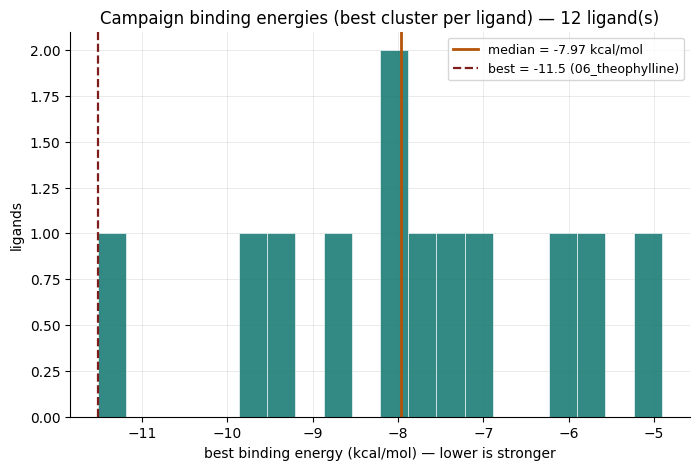

In [37]:
import warnings

from pharmaml.viz import plot_energy_distribution

# Version-compatibility noise from matplotlib/pyparsing in this env.
warnings.filterwarnings("ignore", category=DeprecationWarning)

fig_energy = plot_energy_distribution(
    ok, title="Campaign binding energies (best cluster per ligand)"
)

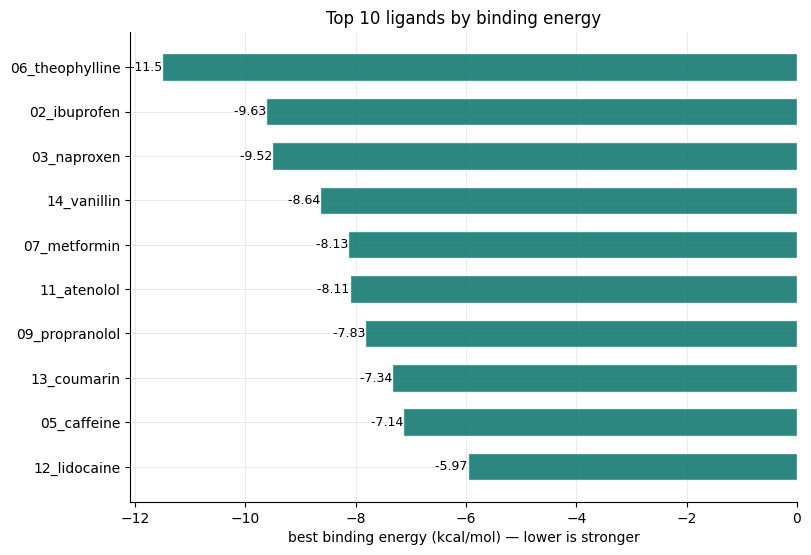

In [38]:
from pharmaml.viz import plot_top_ligands

fig_top = plot_top_ligands(ok, top_n=10, title="Top 10 ligands by binding energy")

## 11 · Publish — the one-click visual bundle

`save_visual_bundle` renders the figures and tables into a directory **and**
a self-contained `report.html` (figures embedded as base64 — no external
assets).  `export_table` writes any table as csv/tsv/markdown/json/html.


In [39]:
from pharmaml.viz import save_visual_bundle

campaign_metrics = {
    "ligands docked": int(len(ok)),
    "failed folders": int((summary["status"] != "OK").sum()),
    "best energy (kcal/mol)": float(ok["best_lowest_energy"].min()),
    "best ligand": str(ok.loc[ok["best_lowest_energy"].idxmin(), "folder"]),
    "median energy (kcal/mol)": float(ok["best_lowest_energy"].median()),
    "mean ligand efficiency": round(float(ok["ligand_efficiency"].mean()), 3),
}

BUNDLE = WORK / "docking_reports"
artifacts = save_visual_bundle(
    figures={"energy_distribution": fig_energy, "top_ligands": fig_top},
    tables={
        "docking_summary": ok[["folder", "n_clusters", "best_lowest_energy",
                               "best_mean_energy", "best_num_in_cluster",
                               "num_heavy_atoms", "ligand_efficiency",
                               "consensus"]],
        "completion_audit": audit,
        "vina_poses": pd.DataFrame([asdict(p) for p in poses]),
    },
    metrics=campaign_metrics,
    out_dir=BUNDLE,
    title="Docking campaign report",
    subtitle=f"{len(ok)} ligands · AutoDock4 demo campaign",
    formats=("png", "svg"),
    close=False,   # keep figures open so they also render above
)
pd.DataFrame({"artifact": [p.name for p in artifacts],
              "kind": [p.suffix.lstrip(".") for p in artifacts]})

,artifact,kind
0,report.html,html
1,docking_summary.csv,csv
2,docking_summary.md,md
3,completion_audit.csv,csv
4,completion_audit.md,md
5,vina_poses.csv,csv
6,vina_poses.md,md
7,energy_distribution.png,png
8,energy_distribution.svg,svg
9,top_ligands.png,png


In [40]:
from pharmaml.viz import export_table

exports = [
    export_table(ok, BUNDLE / "docking_summary.md"),
    export_table(ranked, BUNDLE / "consensus_ranking.csv"),
    export_table(audit, BUNDLE / "completion_audit.json"),
]
report_html = BUNDLE / "report.html"
print(f"{report_html}  ({report_html.stat().st_size / 1024:.0f} KB, zero external assets)")
[p.name for p in exports]

/tmp/docking_workflow_hdriv55x/docking_reports/report.html  (124 KB, zero external assets)


['docking_summary.md', 'consensus_ranking.csv', 'completion_audit.json']

## 12 · The ligand-structure & MGLTools twins — ligprep.py / ligprep_qt.py

The 2026-10 "new folder" upload re-delivered two ligand-side pipelines
the toolkit had only partially absorbed — this section tours both, plus
the Vina config reader its controllers drive:

* **`generate_ligand_structures`** (the upload's `ligprep.py`) — every
  valid SMILES of a library becomes its **canonical tautomer**, is
  embedded as *N* ETKDG conformers, minimised (MMFF, UFF fallback), and
  the **lowest-energy conformer** is written as a one-model PDB **with
  `CONECT` records** (the connectivity `prepare_ligand4.py` reads)
  plus — when OpenBabel is installed — a Gasteiger-charged **MOL2**
  twin. Metal centres (Fe/Zn/Cu/Mn/Co/Ni/Mo/W) are skipped with a
  per-row reason, never aborting the batch.
* **`convert_pdb_folder_to_pdbqt`** (the upload's `ligprep_qt.py`) — a
  folder of PDB files driven through MGLTools'
  `prepare_ligand4.py` into the numbered-sub-folder tree (`1/`, `2/`,
  `3/` …) the campaign readers expect, each conversion guarded by a
  timeout, with the successes/timeouts/failures log written beside it.
* **`parse_vina_config`** — the upload's `vina.conf` / `conf.txt`
  convention: one file carrying the receptor, the grid box and the
  engine knobs, parsed back into the dict the batch runner consumes.


In [41]:
from pharmaml.docking import generate_ligand_structures

# An honest little library: a valid drug, a metal complex the skip list
# refuses, and a broken SMILES -- all three ride the same report.
STRUCT_CSV = WORK / "structure_library.csv"
STRUCT_CSV.write_text(
    "name,SMILES\n"
    "aspirin,CC(=O)Oc1ccccc1C(=O)O\n"
    "zinc_complex,[Zn+2]\n"
    "broken,C1CC\n",
    encoding="utf-8",
)

STRUCT_OUT = WORK / "ligand_structures"
structures = generate_ligand_structures(
    STRUCT_CSV, STRUCT_OUT, num_confs=8, write_mol2=False
)
print(f"files written: {sorted(p.name for p in STRUCT_OUT.iterdir())}")
structures[["ligand", "forcefield", "energy", "conformers", "atoms", "ok", "error"]]


files written: ['aspirin.pdb']


,ligand,forcefield,energy,conformers,atoms,ok,error
0,aspirin,RDKit MMFF,18.9098,8,21,True,
1,zinc_complex,,,0,0,False,unsupported atom(s) Zn (no MMFF/UFF parameteri...
2,broken,,,0,0,False,RDKit could not parse this SMILES


In [42]:
# The PDB carries the connectivity records MGLTools' ligand reader
# needs -- the whole reason ligprep.py wrote its own PDB writer.
aspirin_pdb = (STRUCT_OUT / "aspirin.pdb").read_text(encoding="utf-8")
conect_lines = [line for line in aspirin_pdb.splitlines() if line.startswith("CONECT")]
print(f"{len(conect_lines)} CONECT records; the first three:")
print("\n".join(conect_lines[:3]))


21 CONECT records; the first three:
CONECT    1    2   14   15   16
CONECT    2    1    3    4
CONECT    3    2


In [43]:
from pharmaml.docking import convert_pdb_folder_to_pdbqt

# A self-contained STUB MGLTools pair (the real one is a Windows
# install): the "interpreter" copies its -o argument to a stub .pdbqt,
# so the numbered-subfolder tree, the timeout guard and the conversion
# log all run exactly as they would against prepare_ligand4.py.
MGL_SRC = WORK / "stub_pdbs"
MGL_SRC.mkdir(exist_ok=True)
for stub_name in ("ligand_a", "ligand_b"):
    (MGL_SRC / f"{stub_name}.pdb").write_text(
        "ATOM      1  C   LIG A   1       0.000   0.000   0.000  1.00 20.00     C\n",
        encoding="utf-8",
    )

MGL_PY = WORK / "stub_pythonsh"
MGL_PY.write_text(
    '#!/bin/sh\nout=""\n'
    'while [ $# -gt 0 ]; do case "$1" in -o) out="$2"; shift 2;; *) shift;; esac; done\n'
    'printf "REMARK stub pdbqt\\n" > "$out"\n',
    encoding="utf-8",
)
MGL_PY.chmod(0o755)
MGL_ADT = WORK / "stub_prepare_ligand4.py"
MGL_ADT.write_text("# stub AutoDockTools prepare_ligand4.py\n", encoding="utf-8")

MGL_OUT = WORK / "stub_pdbqt_tree"
conversion = convert_pdb_folder_to_pdbqt(
    MGL_SRC, MGL_OUT, MGL_PY, MGL_ADT, timeout_s=20.0
)
print("numbered tree:", sorted(p.name for p in MGL_OUT.iterdir()))
conversion[["ligand", "subfolder", "status", "seconds", "error"]]


numbered tree: ['1', '2', 'conversion_log.txt']


,ligand,subfolder,status,seconds,error
0,ligand_a,1,converted,0.002,
1,ligand_b,2,converted,0.001,


In [44]:
# The conversion log the original script wrote -- successes, timeouts
# and failures, one plain-text section each.
print((MGL_OUT / "conversion_log.txt").read_text(encoding="utf-8"))


PDB to PDBQT Conversion Log - 2026-11-14 10:44:22

SUCCESSFUL CONVERSIONS:
ligand_a
ligand_b

All PDB files converted successfully.



In [45]:
from pharmaml.docking import parse_vina_config

# The upload's own vina.conf values (Vina/ and Vina_contol/conf.txt):
# the grid centre and size of its demo box, its num_modes and its
# production-grade exhaustiveness.
UPLOAD_CONF = WORK / "upload_vina.conf"
UPLOAD_CONF.write_text(
    "# Receptor and ligand input files\n"
    "receptor = r.pdbqt\n"
    "\n"
    "center_x = 129.139\n"
    "center_y = 122.269\n"
    "center_z = 134.375\n"
    "\n"
    "size_x = 96\n"
    "size_y = 126\n"
    "size_z = 126\n"
    "\n"
    "num_modes = 40\n"
    "exhaustiveness = 48\n"
    "energy_range = 3\n",
    encoding="utf-8",
)
vina_params = parse_vina_config(UPLOAD_CONF)
vina_params


{'receptor': 'r.pdbqt',
 'center_x': '129.139',
 'center_y': '122.269',
 'center_z': '134.375',
 'size_x': '96',
 'size_y': '126',
 'size_z': '126',
 'num_modes': '40',
 'exhaustiveness': '48',
 'energy_range': '3'}

In [46]:
from pharmaml.docking import run_vina_batch, vina_batch_progress
from pharmaml.exceptions import DockingError

# The pre-flight census (batch_vina.py's resume rule, library edition):
# a ligand whose <stem>_out.pdbqt AND non-empty <stem>.log exist is
# "already docked" -- the SAME skip rule and the SAME collision-
# disambiguated naming the run itself uses, so the count is a promise
# a resumed run keeps.
VBATCH_LIGANDS = WORK / "vbatch_ligands"
VBATCH_LIGANDS.mkdir(exist_ok=True)
for stem in ("lig01", "lig02", "lig03"):
    (VBATCH_LIGANDS / f"{stem}.pdbqt").write_text("REMARK ligand\n", encoding="utf-8")

VBATCH_OUT = WORK / "vbatch_out"
VBATCH_OUT.mkdir(exist_ok=True)
# lig01 already docked (output + non-empty log); lig02's zero-byte log
# marks a CRASHED job (a redo, not a skip); lig03 never started
(VBATCH_OUT / "lig01_out.pdbqt").write_text(
    "REMARK VINA RESULT:    -7.1      0.000      0.000\n", encoding="utf-8"
)
(VBATCH_OUT / "lig01.log").write_text(
    "Estimated Free Energy of Binding   = -7.1 (kcal/mol)\n", encoding="utf-8"
)
(VBATCH_OUT / "lig02.log").write_text("", encoding="utf-8")

census = vina_batch_progress(VBATCH_LIGANDS, VBATCH_OUT)
print(f"{census.docked}/{census.total} already docked · {census.remaining} to go")
print(f"name collisions: {census.collisions}")

# The engine gate fires BEFORE queue time (no vina binary here) -- the
# same honest DockingError the walkthrough's sequential cell shows, now
# with the workers>1 pool the Playground's Vina-batch card exposes:
try:
    run_vina_batch(
        UPLOAD_CONF, VBATCH_LIGANDS, VBATCH_OUT,
        max_parallel=2, skip_existing=True,
    )
except DockingError as exc:
    print(f"[run_vina_batch max_parallel=2] {exc}")


1/3 already docked · 2 to go
name collisions: 0
[run_vina_batch max_parallel=2] vina.exe is a Windows PE executable and no wine was found on PATH -- run it on Windows, install compatible wine, or use a native engine build


## 13 · Contact map & PLIF — the pose-level reading

The energy table says *how strongly*; the contact map says *where*.
`read_pdb_atoms` takes the real 1AKI lysozyme (§2's receptor, unchanged),
`read_pdbqt_atoms` the bundled `contacts_demo_ligand.pdbqt` — ten
synthetic atoms placed clash-free at 2.9–4.2 Å from real binding-cleft
atoms (ASP52/101 carboxylates, ASN59/103 donors, the TRP62/63/108 walls;
a documented geometry demo, the twin of the synthetic r.dlg campaign —
the REMARK lines inside carry the provenance). `compute_contacts`
classifies every pair within the 5 Å shell; `contact_matrix`/`plif_matrix`
aggregate it; the two figures below are the map and the fingerprint.


In [47]:
from pharmaml.docking import (
    compute_contacts, plif_matrix, read_pdb_atoms, read_pdbqt_atoms,
)

receptor_atoms = read_pdb_atoms(DATA_DIR / "lysozyme_1aki.pdb")
pose_atoms = read_pdbqt_atoms(DATA_DIR / "contacts_demo_ligand.pdbqt")
contacts = compute_contacts(pose_atoms, receptor_atoms, cutoff=5.0)
plif = plif_matrix(contacts)
print(f"{len(contacts)} contacts over {plif.shape[0]} residues — "
      f"{int(plif['salt_bridge'].sum())} salt bridge(s), "
      f"{int(plif['hbond'].sum())} H-bond(s), "
      f"{int(plif['hydrophobic'].sum())} hydrophobic")
plif.head(12)


91 contacts over 25 residues — 3 salt bridge(s), 3 H-bond(s), 24 hydrophobic


,salt_bridge,hbond,hydrophobic,vdw,total
A:ASN103,0,2,0,4,6
A:LEU56,0,0,3,1,4
A:ASP101,1,0,0,6,7
A:ALA31,0,0,1,2,3
A:HOH178,0,0,0,2,2
A:TRP62,0,1,2,7,10
A:ASN59,1,0,1,5,7
A:TRP28,0,0,4,4,8
A:MET105,0,0,1,1,2
A:TRP63,0,0,1,4,5


closest contact: O2 to A:ASN103 OD1 3.00 Å (hbond)


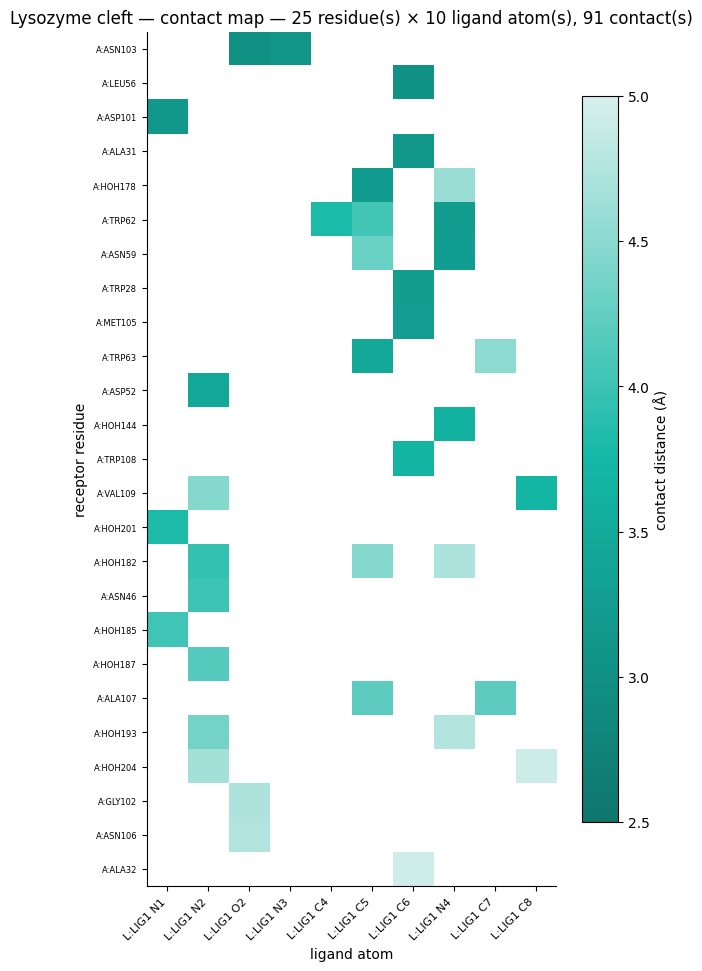

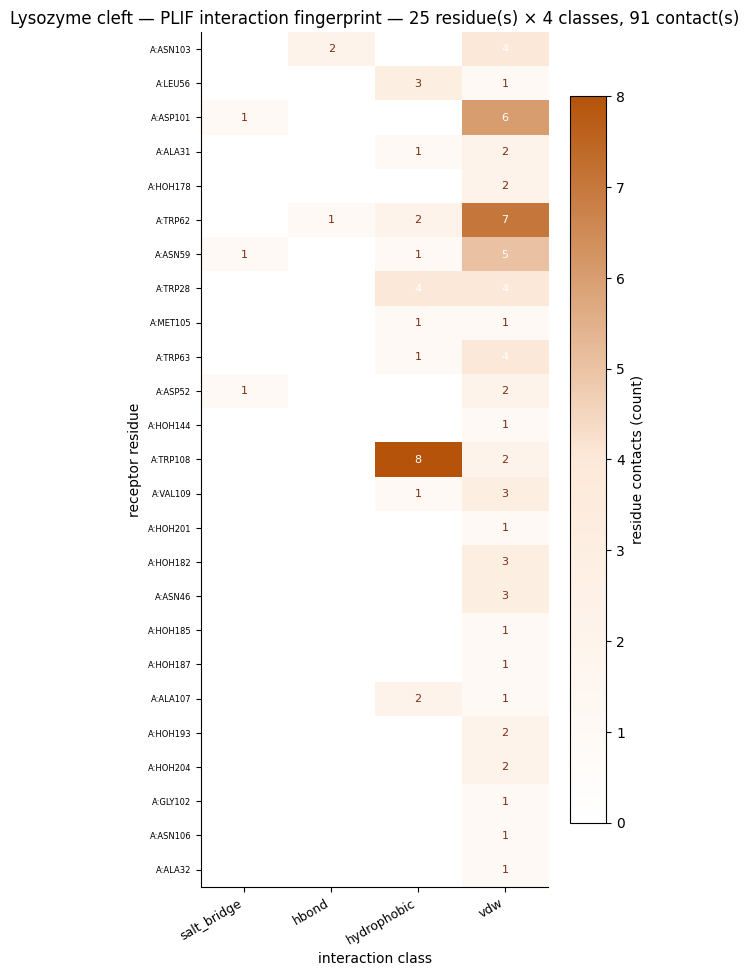

In [48]:
from pharmaml.viz import plot_contact_map, plot_plif_heatmap

fig_contacts = plot_contact_map(
    contacts, title="Lysozyme cleft — contact map")
fig_plif = plot_plif_heatmap(contacts, title="Lysozyme cleft — PLIF")
print("closest contact:", contacts[0].ligand_atom.name, "to",
      contacts[0].receptor_atom.label, f"{contacts[0].distance:.2f} Å",
      "(" + contacts[0].interaction + ")")


## 14 · Recap

| Stage | One-liner |
|---|---|
| Import ligand CSV | `load_ligand_csv(ligands.csv)` → validated `LigandLibrary` |
| Batch ligand prep | `prepare_ligand_library(library, out_dir)` → folder-per-ligand tree |
| Import & prep protein | `prepare_protein(protein.pdb, r.pdbqt)` → cleaned, typed, charged receptor |
| Distribute receptor | `distribute_receptor(r.pdbqt, campaign_root)` |
| Single ligand | `smiles_to_pdbqt(smiles, out_dir, name=...)` |
| Ligand structures | `generate_ligand_structures(library, out_dir, num_confs=50)` → lowest-energy PDB (+ MOL2) | 
| MGLTools PDB→PDBQT | `convert_pdb_folder_to_pdbqt(pdbs, out, mgl_python, adt_script)` → numbered tree + log |
| Vina config | `parse_vina_config(conf.txt)` → the box + engine knobs |
| Resume census | `vina_batch_progress(ligands, out)` → N docked · M to go |
| Grid box | `compute_grid_box(reference_ligand.pdbqt, padding=4)` |
| GPF file | `write_gpf(ligand.pdbqt, box=box)` |
| DPF file | `write_dpf(ligand.pdbqt, ga_run=100)` |
| Torsion QA | `scan_torsion_consistency(ligand_dir)` → OK / MISMATCH |
| Run AutoDock4 | `run_autodock4(ligand_dir)` / `batch_run_directories(base)` |
| Run Vina | `run_vina(receptor, ligand, out, center, size)` |
| One ligand | `parse_dlg_summary(r.dlg)` |
| Audit campaign | `check_docking_completion(docking_run)` |
| Scan campaign | `scan_docking_directory(docking_run)` |
| Campaign sweep | `collect_files(tree, dry_run=True)` / `cleanup_tree(tree, keep={"r.dlg"})` |
| Vina poses | `parse_vina_output(out.pdbqt)` |
| Rescore | `ligand_efficiency_series(frame)` + `consensus_rescore(frame, cols)` + `consensus_breakdown(frame, cols)` |
| Visualize | `plot_energy_distribution(summary)` / `plot_top_ligands(summary)` |
| Publish | `save_visual_bundle(figures, tables, metrics, "reports")` |

CLI equivalents:

```bash
pharmaml docking prep-ligands --ligands ligands.csv --out ligand_folders/
pharmaml docking prep-protein --protein protein.pdb --out r.pdbqt
pharmaml docking scan      --directory docking_run/ --out summary.csv
pharmaml docking check     --directory docking_run/
```
